# Does body mass explain how long an animal lives?

**Research question.** Across animal species, how strongly does body mass explain maximum
longevity, and does the relationship hold equally for mammals and birds?

**Data.** AnAge database (Human Ageing Genomic Resources), file `data/anage_data.csv`.
One row per species, with body mass in grams and maximum recorded longevity in years.


## 1. Load and inspect

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.width', 120)

df = pd.read_csv('data/anage_data.csv')
print('rows, columns:', df.shape)

rows, columns: (4218, 30)


In [2]:
df.columns.tolist()

['Unnamed: 0',
 'HAGRID',
 'Kingdom',
 'Phylum',
 'Class',
 'Order',
 'Family',
 'Genus',
 'Species',
 'Common name',
 'Female maturity (days)',
 'Male maturity (days)',
 'Gestation/Incubation (days)',
 'Weaning (days)',
 'Litter/Clutch size',
 'Litters/Clutches per year',
 'Inter-litter/Interbirth interval',
 'Birth weight (g)',
 'Weaning weight (g)',
 'Adult weight (g)',
 'Growth rate (1/days)',
 'Maximum longevity (yrs)',
 'Specimen origin',
 'Sample size',
 'Data quality',
 'IMR (per yr)',
 'MRDT (yrs)',
 'Metabolic rate (W)',
 'Body mass (g)',
 'Temperature (K)']

## 2. Select the two variables of interest

In [3]:
# pick the columns by name pattern so the notebook does not depend on exact headers
mass_col = [c for c in df.columns if c.lower().startswith('body mass')][0]
long_col = [c for c in df.columns if 'longevity' in c.lower()][0]
class_col = 'Class'
print('mass:', mass_col, '| longevity:', long_col, '| class:', class_col)
print(df[[mass_col, long_col, class_col]].isna().sum())

mass: Body mass (g) | longevity: Maximum longevity (yrs) | class: Class
Body mass (g)              3591
Maximum longevity (yrs)     442
Class                         0
dtype: int64


## 3. Clean the data

In [4]:
keep = [mass_col, long_col, class_col, 'Common name', 'Species']
d = df[keep].dropna(subset=[mass_col, long_col]).copy()
d = d[(d[mass_col] > 0) & (d[long_col] > 0)]
d['log_mass'] = np.log10(d[mass_col])
d['log_longevity'] = np.log10(d[long_col])
print('usable species:', len(d))
d[class_col].value_counts().head(8)

usable species: 546


Class
Mammalia    349
Aves        167
Amphibia     16
Reptilia     14
Name: count, dtype: int64

## 4. Overall relationship (figure 1)

In [5]:
slope, intercept = np.polyfit(d['log_mass'], d['log_longevity'], 1)
pred = slope * d['log_mass'] + intercept
ss_res = ((d['log_longevity'] - pred) ** 2).sum()
ss_tot = ((d['log_longevity'] - d['log_longevity'].mean()) ** 2).sum()
r2 = 1 - ss_res / ss_tot
r = np.corrcoef(d['log_mass'], d['log_longevity'])[0, 1]
print(f'slope = {slope:.3f}, r = {r:.3f}, R2 = {r2:.3f}, n = {len(d)}')

slope = 0.143, r = 0.529, R2 = 0.280, n = 546


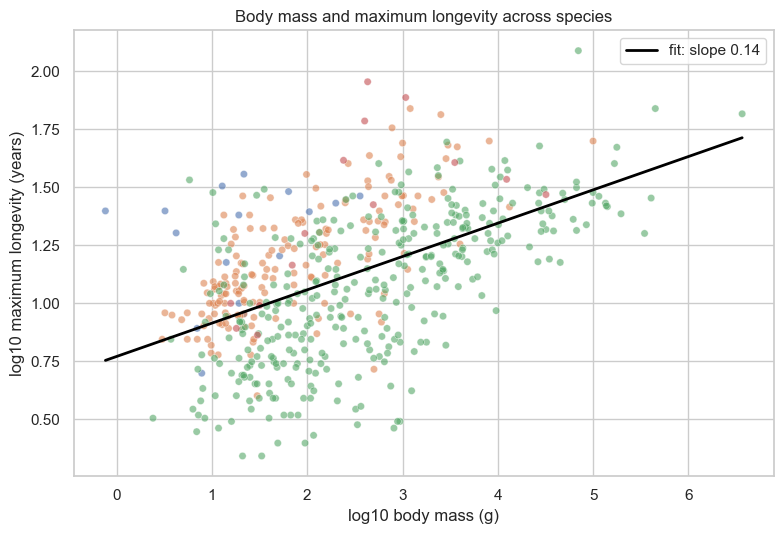

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=d, x='log_mass', y='log_longevity', hue=class_col,
                alpha=0.6, s=28, ax=ax, legend=False)
xs = np.linspace(d['log_mass'].min(), d['log_mass'].max(), 50)
ax.plot(xs, slope * xs + intercept, color='black', lw=2, label=f'fit: slope {slope:.2f}')
ax.set_xlabel('log10 body mass (g)')
ax.set_ylabel('log10 maximum longevity (years)')
ax.set_title('Body mass and maximum longevity across species')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig1_mass_vs_longevity.png', dpi=150)
plt.show()

## 5. Mammals vs birds (figure 2)

In [7]:
two = d[d[class_col].isin(['Mammalia', 'Aves'])].copy()
rows = []
for cls, g in two.groupby(class_col):
    s, i = np.polyfit(g['log_mass'], g['log_longevity'], 1)
    p = s * g['log_mass'] + i
    rr = 1 - ((g['log_longevity'] - p) ** 2).sum() / ((g['log_longevity'] - g['log_longevity'].mean()) ** 2).sum()
    rows.append({'class': cls, 'n': len(g), 'slope': round(s, 3), 'R2': round(rr, 3),
                 'median_longevity_yr': round(g[long_col].median(), 2)})
pd.DataFrame(rows)

,class,n,slope,R2,median_longevity_yr
0,Aves,167,0.207,0.508,13.5
1,Mammalia,349,0.183,0.439,12.0


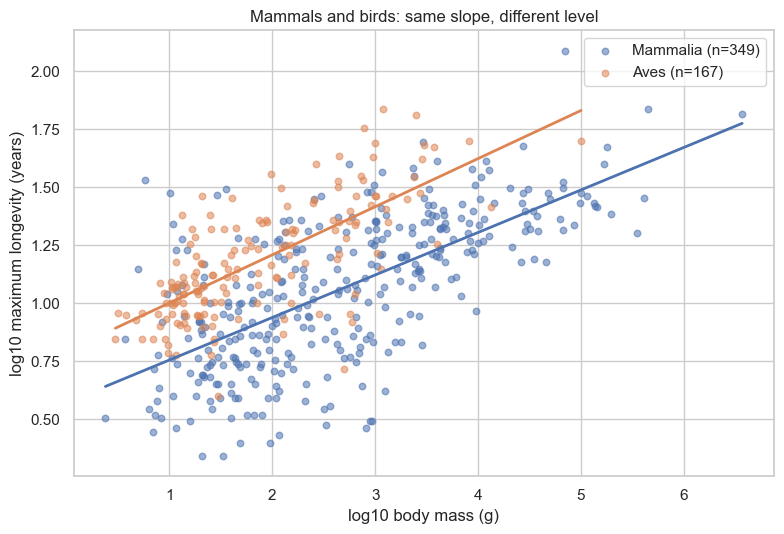

In [8]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for cls, color in [('Mammalia', '#4c72b0'), ('Aves', '#dd8452')]:
    g = two[two[class_col] == cls]
    s, i = np.polyfit(g['log_mass'], g['log_longevity'], 1)
    ax.scatter(g['log_mass'], g['log_longevity'], s=22, alpha=0.55, color=color, label=f'{cls} (n={len(g)})')
    xs = np.linspace(g['log_mass'].min(), g['log_mass'].max(), 30)
    ax.plot(xs, s * xs + i, color=color, lw=2)
ax.set_xlabel('log10 body mass (g)')
ax.set_ylabel('log10 maximum longevity (years)')
ax.set_title('Mammals and birds: same slope, different level')
ax.legend()
plt.tight_layout()
plt.savefig('figures/fig2_mammals_vs_birds.png', dpi=150)
plt.show()

## 6. Findings

1. **The relation is positive but loose.** Across the 546 species that report both numbers, the
   correlation between log10 body mass and log10 maximum longevity is r = 0.53 and the fit explains
   R2 = 0.28 of the variance. Body mass is a real predictor, but it leaves most of the variation
   unexplained.

2. **The slope is shallow.** The overall log-log slope is 0.143, so a ten-fold increase in mass goes
   with only about a 1.39-fold increase in maximum longevity. Big animals live longer, but far from
   proportionally longer.

3. **Birds sit above mammals.** The two groups have similar slopes (0.183 for mammals, 0.207 for birds)
   but different intercepts: at a body mass of 100 g the fitted longevity is about 8.7 years for a
   mammal and about 16.2 years for a bird. Class therefore carries information that mass does not.

**Limitation.** Maximum longevity is a record value, not an average lifespan, so it depends on how many
individuals have been observed and for how long; well-studied species are biased upward. The data are
also only 546 species out of 4218 rows, because 3591 rows do not report body mass, and the study is
observational, so nothing here shows that body mass causes longevity.
